# Лабораторная работа 3

## Сингулярное разложение и его приложения

Напомним, что сингулярным разложением (SVD, Singular value decomposition) матрицы $A$ размера $m\times n$ называется представление

$$A = U\Sigma V^T,$$

где $U$ — ортогональная матрица размера $m\times m$, $V$ — ортогональная матрица размера $n\times n$, $\Sigma = \mathrm{diag}(\sigma_1,\sigma_2,\sigma_3,\ldots)$ — диагональная матрица размера $m\times n$, в которой $\sigma_1\geqslant\sigma_2\geqslant\ldots\geqslant0$.

На самом деле требование, чтобы матрицы $U$ и $V$ были квадратными, избыточно. *Усечённым сингулярным разложением* мы будем называть разложение

$$A = U\Sigma V^T,$$

где $U$ и $V$ — матрицы с ортонормированными столбцами размеров $m\times k$ и $n \times k$ соответственно, $\Sigma$ — диагональная матрица размера $k\times k$, где $k = \min(m,n)$. Далее мы будем работать исключительно с усечённым разложением.

### Сжатие данных с помощью SVD = построение низкорангового приближения

Введём *норму Фробениуса* матрицы как

$$||A||_{frob} = \sqrt{\mathrm{tr}{A^TA}} = \sqrt{\sum\limits_{i,j}a^2_{i,j}}$$

Иными словами, это обычное евклидово расстояние на пространстве, которое получается, если все матрицы вытянуть в длинные векторы.

Зададимся вопросом: как найти матрицу $A_{r}$ ранга $r$, наименее отличающуюся от $A$ по норме Фробениуса (то есть для которой норма разности $||A - A_{r}||_{frob}$ минимальна). Оказывается, это можно сделать с помощью сингулярного разложения:

**Теорема.** Пусть $\Sigma_{r}$ — это матрица, полученная из $\Sigma$ заменой диагональных элементов $\sigma_{i}$ ($i > r$) нулями, тогда $A_{r} = U\Sigma_{r}V^T$.

Это можно переписать и в более экономичном виде. Если

$$A = \underbrace{
\begin{pmatrix}
u_{11} & \ldots & u_{1k}\\
\vdots & & \vdots\\
u_{m1} & \ldots & u_{mk}
\end{pmatrix}}_{=U}\cdot\underbrace{{
\begin{pmatrix}
\sigma_{1} & &\\
 & \sigma_{2} & \\
 & & \ddots
\end{pmatrix}}
}_{=\Sigma}\cdot \underbrace{
\begin{pmatrix}
v_{11} & \ldots & v_{n1}\\
\vdots & & \vdots\\
v_{1k} & \ldots & v_{nk}
\end{pmatrix}}_{=V^T}$$

то

$$A_{r} = \underbrace{
\begin{pmatrix}
u_{11} & \ldots & u_{1r}\\
\vdots & & \vdots\\
u_{m1} & \ldots & u_{mr}
\end{pmatrix}}_{=U_r}\cdot\underbrace{{
\begin{pmatrix}
\sigma_{1} & &\\
 & \ddots & \\
 & & \sigma_{r}
\end{pmatrix}}
}_{=\Sigma_r}\cdot \underbrace{
\begin{pmatrix}
v_{11} & \ldots & v_{n1}\\
\vdots & & \vdots\\
v_{1r} & \ldots & v_{nr}
\end{pmatrix}}_{=V^T_r}$$

При этом

$$||A - A_{r}||_{frob} = \sqrt{\sum\limits_{i\geqslant r+1} \sigma_{i}^2}$$

Если сингулярные значения матрицы падают достаточно быстро (а в реальных задачах часто бывает именно так), то норма разности будет малой при сравнительно небольшом значении $r$.

На хранение исходной матрицы нам требовалось $m\times n$ памяти. Теперь же, если мы будем хранить отдельно $U_r$, $V_r$ и диагональные элементы $\Sigma_r$, затраты памяти составят $mr + nr + r = r(m + n + 1)$.

**Разложение на компоненты ранга 1**

Обозначим через $u_1,\ldots, u_k$ столбцы матрицы $U$, а через $v_1, \ldots, v_k$ столбцы матрицы $V$. Тогда имеет место равенство

$$A = u_1\sigma_{1}v_1^T + u_2\sigma_{2}v_2^T + u_3\sigma_{3}v_3^T + \ldots$$

Матрицу $u_k\sigma_{k}v_k^T = \sigma_{k}u_kv_k^T$ мы будем называть $k$-й компонентой ранга 1 матрицы $A$. Отметим, что слагаемые в этой сумме ортогональны относительно скалярного произведения $(X, Y) = \mathrm{tr}(X^TY)$ (порождающего норму Фробениуса).

Как нетрудно заметить,

$$A_{r} = \sigma_{1}u_1v_1^T + \sigma_{2}u_2v_2^T + \ldots + \sigma_{r}u_rv_r^T$$

**Технические детали (SVD в Питоне)**

Есть несколько способов сделать в Питоне сингулярное разложение; мы пока предлагаем Вам использовать

`import scipy.linalg as sla`

`U, S, Vt = sla.svd(X, full_matrices=False)`

Для ознакомления с особенностями этой функции рекомендуем обратиться к [документации](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.svd.html) (в частности, обратите внимание на то, какие именно объекты она возвращает).

### Правила оформления графиков

При работе с данными часто неудобно делать какие-то выводы, если смотреть на таблицу и числа в частности, поэтому важно уметь визуализировать данные.

У matplotlib, конечно же, есть [документация](https://matplotlib.org/users/index.html) с большим количеством [примеров](https://matplotlib.org/examples/), но для начала достаточно знать про несколько основных типов графиков:
- plot — обычный поточечный график, которым можно изображать кривые или отдельные точки;
- hist — гистограмма, показывающая распределение некоторой величины;
- scatter — график, показывающий взаимосвязь двух величин;
- bar — столбцовый график, показывающий взаимосвязь количественной величины от категориальной.

Ещё одна билиотека для визуализации: [seaborn](https://jakevdp.github.io/PythonDataScienceHandbook/04.14-visualization-with-seaborn.html). Это настройка над matplotlib, иногда удобнее и красивее делать визуализации через неё.

Не забывайте про базовые принципы построения приличных графиков:
- оси должны быть подписаны, причём не слишком мелко;
- у графика должно быть название;
- если изображено несколько графиков, то необходима поясняющая легенда;
- для точек из разных выборок, необходимо использовать разные цвета;
- все линии на графиках должны быть чётко видны (нет похожих цветов или цветов, сливающихся с фоном);
- размер графика должен быть таким, чтобы по нему несложно было сделать необходимые выводы о данных;
- если отображена величина, имеющая очевидный диапазон значений (например, проценты могут быть от 0 до 100), то желательно масштабировать ось на весь диапазон значений (исключением является случай, когда вам необходимо показать малое отличие, которое незаметно в таких масштабах).

Помните, что проверяющий имеет право снизить оценку за неопрятные графики.

### Оценивание

Обратите внимание, что в каждом разделе есть задания на написания кода и есть вопросы. Вопросы дополняют задачи и направлены на то, чтобы проинтерпретировать или обосновать происходящее. Код без интерпретации не имеет смысла, поэтому отвечать на вопросы обязательно — за отсутствие ответов мы будем снижать баллы за задачи. Если Вы ответите на вопросы, но не напишете корректный код к соответствующим оцениваемым задачам, то в подавляющем большинстве случаев баллы за такое выставлены не будут.

### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате homework-practice-03-linregr-Username.ipynb, где Username — Ваша фамилия.

### Задание 1. Сжатие данных с помощью SVD

Загрузите выложенную на странице курса фотографию.

In [3]:
import numpy as np
from skimage.io import imread

img = imread(r'chain_small.JPG')
img = img.mean(axis=2) # это матрица из интенсивностей серого цвета; её уже можно подвергать SVD

Нарисуйте картинку:

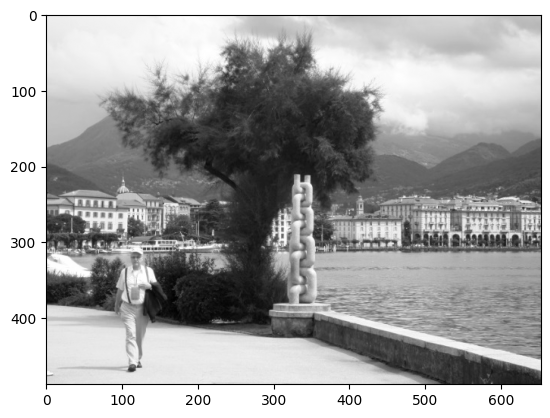

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline

imgplot = plt.imshow(img, cmap='gray')

Постройте сингулярное разложение этой матрицы.

In [5]:
from numpy.linalg import svd

U, S, VT = svd(img, full_matrices=False)

**1. [0.1 балла]** Нарисуйте график диагональных элементов матрицы $\Sigma$:

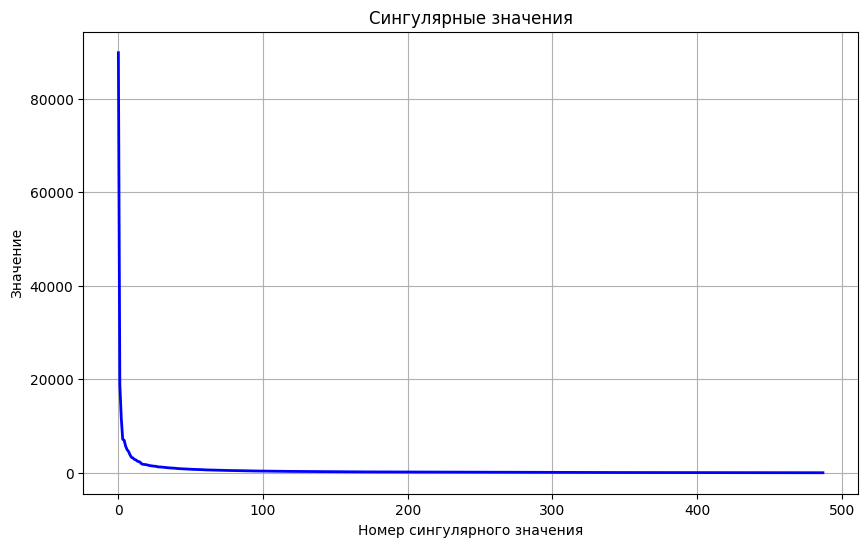

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(S, 'b-', linewidth=2)
plt.title('Сингулярные значения')
plt.xlabel('Номер сингулярного значения')
plt.ylabel('Значение')
plt.grid(True)
plt.show()

Кажется, что они убывают достаточно быстро и есть надежда, что первые несколько компонент дадут картинку, близкую к исходной.

**Важно:** при визуализации различных компонент в этом задании используйте только матричные операции. В частности, избегайте циклов, функций `map` и `reduce`, а также специальных функций, находящих суммы компонент.

`**2. [0.1 балла]** Визуализуйте первую компоненту ранга 1. Ожидали ли Вы увидеть именно это? Поясните.

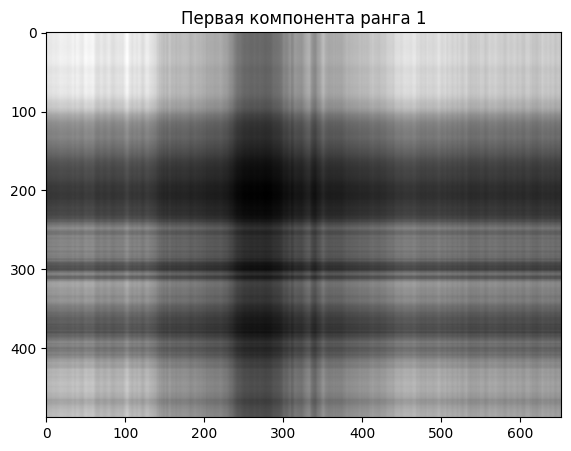

In [7]:
rank1 = S[0] * U[:, [0]] @ VT[[0], :]
plt.figure(figsize=(10, 5))
plt.imshow(rank1, cmap='gray')
plt.title('Первая компонента ранга 1')
plt.show()

Заметим, что первая компонента ранга 1 достаточно точно передает силуэты исходонй картинки: например, темная линия, параллельная $Oy$, находящаяся примерно на интервале $[250; 300]$ по $Ox$ соответствует темному дереву на картинке, светлые участки соответствуют светлым предметам на картинке, таким как вода или тротуар. Мы знаем, что сингулярные значения расположены по убыванию ($\sigma_1 \geq \sigma_2 \geq .... \geq \sigma_n > 0$), поэтому первая компонента ранга 1 - самое главное, что есть в изображении. Она содержит наиболее значимую информацию, поэтому так хорошо передает структуру изображения. Поэтому, я считаю, получился ожидаемый результат

**3. [0.5 балла]** Визуализуйте суммы компонент ранга 1 с первой по двадцатую, с первой по пятидесятую, с двадцатой по сотую, с двадцатой по последнюю. Сделайте выводы.

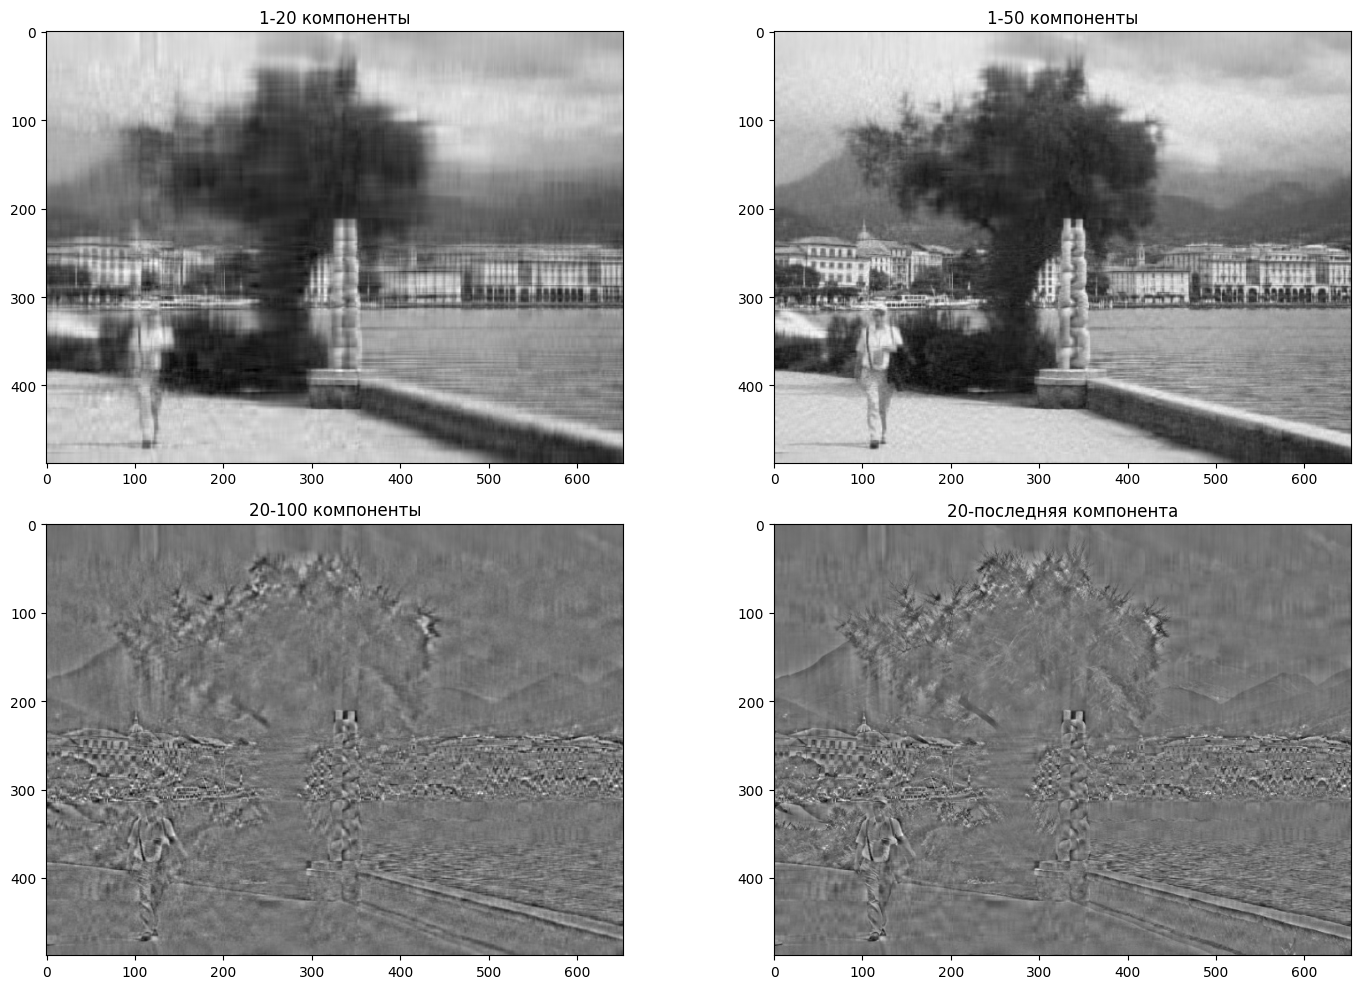

In [8]:
def rank_k(k_start, k_end):
    Uk = U[:, k_start:k_end]
    Sk = S[k_start:k_end]
    VTk = VT[k_start:k_end, :]
    return Uk @ np.diag(Sk) @ VTk

img1 = rank_k(0, 20)
img2= rank_k(0, 50)
img3 = rank_k(19, 100)
img4 = rank_k(19, -1)

plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.imshow(img1, cmap='gray')
plt.title('1-20 компоненты')

plt.subplot(2, 2, 2)
plt.imshow(img2, cmap='gray')
plt.title('1-50 компоненты')

plt.subplot(2, 2, 3)
plt.imshow(img3, cmap='gray')
plt.title('20-100 компоненты')

plt.subplot(2, 2, 4)
plt.imshow(img4, cmap='gray')
plt.title('20-последняя компонента')
plt.tight_layout()
plt.show()

Можно заметить, что если мы начинаем с 1 компоненты, то чем больше компонент мы просуммируем, тем точнее получается изображение. Если мы начинаем с 20 компоненты, то в любом случае получается абсолютно непонятное непохожее изображение. Это как раз связано с тем, что первые компоненты содержат более значимую информацию об изображении: ($\sigma_1 \geq \sigma_2 \geq .... \geq \sigma_n > 0$)

**4. [0.35 балла]** Как Вам кажется, какие компоненты нужно взять для достаточно хорошего восстановления исходного изображения? Аргументируйте свой ответ. Не забудьте визуализировать сумму выбранных компонент.

*Комментарий: для получения полного балла за это задания постарайтесь привести более убедительный аргумент, нежели Ваши субъективные впечатления от сравнения полученного изображения с исходным.*

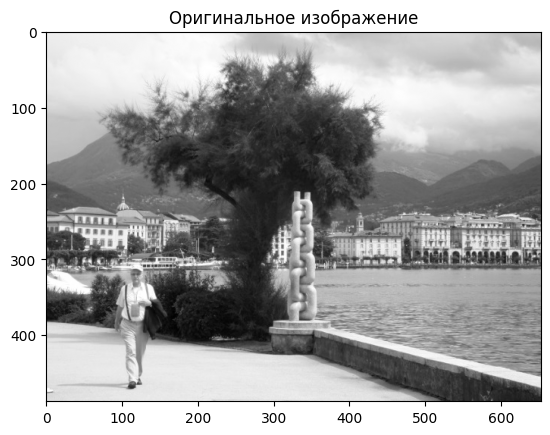

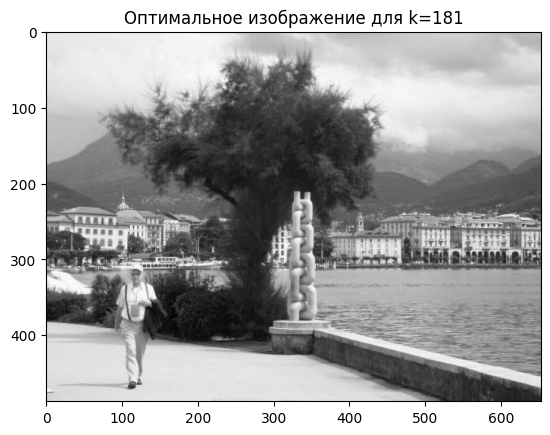

Количество компонент в оригинальном изображении: 488
Количество компонент в оптимальном изображении: 181


In [9]:
norm = np.linalg.norm(S)
for i in range(1, len(S)):
    S_i = S[:i]
    norm_i = np.linalg.norm(S_i)
    if norm_i / norm > 0.9999:
        k = i
        break;

new_img = U[:, :k] @ np.diag(S_i) @ VT[:k, :]

plt.title("Оригинальное изображение")
plt.imshow(img, cmap='gray')
plt.show()

plt.title(f"Оптимальное изображение для k={k}")
plt.imshow(new_img, cmap='gray')
plt.show()
print(f"Количество компонент в оригинальном изображении: {len(S)}")
print(f"Количество компонент в оптимальном изображении: {k}")

Найдем норму Фробениуса изначальной матрицы. Теперь будем искать такую матрицу, которая наименее отличается от изначальной по норме Фробениуса. Будем проходиться в цикле по матрицам пока норма Фробениуса новой матрицы не составит $0,9999(99,99 $%) от нормы Фробениуса изначальной матрицы. Это и будет матрица, соответствующая оптимальному изображению. Также стоит упомянуть, что нужно начинать с самой первой компоненты, так как в начальных компонентах находится значительно больше информации, чем в следующих ($\sigma_1 \geq \sigma_2 \geq .... \geq \sigma_n > 0$)

**5. [0.15 балла]** Во сколько раз меньше памяти (теоретически) потребуется для хранения нового изображения по сравнению с исходным?

In [10]:
m,n=np.shape(img)
print(m,n)
print(n*m)
print(k*(m+n+1))
print(n*m/(k*(m+n+1)))

488 653
318664
206702
1.5416590066859537


Начальная матрица размером $488 \times 653 \Rightarrow $ для ее хранения требуется $488 \cdot 653 = 318664$ ячеек памяти

Для хранения только $181$ первых компонент требуется $181 \cdot (488+653+1) = 206702$ ячейки памяти

Посчитаем отношение: $\frac{318664}{206702} \approx 1,54 \Rightarrow$ потребуется в $1,54$ раза меньше памяти

**6. [0.25 балла]** Подсчитайте, сколько в действительности места в памяти компьютера занимают исходная матрица и компоненты её сингулярного разложения. Согласуется ли этот результат с ответом предыдущего пункта? Сделайте выводы.

In [11]:
U_k = U[:, :k].copy()
S_k = S[:k].copy()
VT_k = VT[:k, :].copy()
size2 = U_k.nbytes + S_k.nbytes + VT_k.nbytes
print(f'Память на оптимальное изображение:{size2}')
size1 = img.nbytes
print(f'Память на оригинальное изображение:{size1}')
result = size1 / size2
print(f'Отношение количеств памяти: {result}')

Память на оптимальное изображение:1653616
Память на оригинальное изображение:2549312
Отношение количеств памяти: 1.5416590066859537


Получилось то же самое отношение. Этот результат согласуется с ответом предыдущего пункта

### Задание 2. Геометрия SVD. Визуализация данных с помощью SVD

**Геометрический смысл SVD**

Допустим, что у нас есть выборка $x_1,\ldots,x_m\in\mathbb{R}^n$. Запишем её в матрицу объекты-признаки

$$X = \begin{pmatrix}
x_{11} & \ldots & x_{1n}\\
\vdots & & \vdots\\
x_{m1} & \ldots & x_{mn}
\end{pmatrix}$$

(строки — объекты, столбцы — признаки) и сделаем SVD-разложение: $X = U\Sigma V^T$. Его можно интерпретировать следующим образом:

$$X = U\Sigma\cdot V^T,$$

где $U\Sigma$ — это матрица объекты-признаки для тех же объектов, но в новых признаках, полученных из исходных с помощью линейного преобразования $V$ (напоминаем, что умножение на матрицу справа соответствует преобразованию столбцов). Попробуем понять, чем замечательны эти признаки.

Рассмотрим матрицу $X^TX = V\Sigma^2V^T$. Легко видеть, что это матрица Грама системы столбцов матрицы $X$; иными словами, в ней записаны скалярные произведения векторов различных признаков. Из лекций вы знаете, что $\sigma_1^2$, квадрат первого сингулярного числа, это наибольшее собственное значение матрицы $X^TX$, а $v_1$, первый столбец матрицы $V$, — это соответствующий собственный вектор. Можно показать, что

$$\sigma_1 = \mathrm{max}_{w}\frac{|Xw|}{|w|} = \mathrm{max}_{|w| = 1}\left(|Xw|\right).$$

Попробуем осознать физический смысл этой штуки. Напомним, что строки матрицы $X$ — это координаты объектов $x_1,\ldots,x_m$ в пространстве признаков. Произведение $Xw$ — это вектор из значений на тех же самых объектах некоторого нового признака, являющегося линейной комбинацией исходных с коэффициентами $w_1,\ldots,w_n$:

$$Xw = w_1\begin{pmatrix} x_{11}\\ \ldots \\ x_{m1}
\end{pmatrix} + w_2\begin{pmatrix} x_{12}\\ \ldots \\ x_{m2}
\end{pmatrix} + \ldots + w_n\begin{pmatrix} x_{1n}\\ \ldots \\ x_{mn}
\end{pmatrix}$$

Соответственно, $|Xw|^2$ — это квадрат длины вектора, составленного из значений нового признака.

Таким образом, первому сингулярному значению $\sigma_1$ отвечает такой признак, у которого сумма квадратов значений максимальна, то есть признак, принимающий, условно говоря, самые большие значения.

Резюмируя, мы можем сказать, что сингулярное разложение делает следующее:
- находит новый признак (новое направление) вдоль которого "дисперсия"$^1$ максимальна;
- в ортогональной ему плоскости находит признак, вдоль которого "дисперсия" максимальна;
- и так далее.

---
$^1$ настоящая выборочная дисперсия с точностью до числового множителя была бы равна $|Xw - \overline{Xw}|^2$, где $\overline{Xw} = \frac1m\sum_{i=1}^m(Xw)_i$ — среднее значения признака.

**1. [1.25 балла]** Пусть $\sigma_1$ — старшее сингулярное число матрицы $X$ размера $m \times n$. Покажите, что верна цепочка равенств
$$\sigma_1 = \mathrm{max}_{w}\frac{|Xw|}{|w|} = \mathrm{max}_{|w| = 1}~|Xw| = \mathrm{max}_{|u|=|v| = 1}~|u^T Xv|.$$

**Подсказки:**
* при доказательстве равенства $\sigma_1 = \mathrm{max}_{w}\frac{|Xw|}{|w|}$ выразите вектор $w$ как $\alpha\cdot v$, где $|v|=1$, и рассмотрите описанное выражение
* при доказательстве равенства $\sigma_1 = \mathrm{max}_{|w| = 1}~|Xw|$ представьте $w$ в виде линейной комбинации ортонормированного базиса, состоящего из собственных векторов оператора $X^TX$, и внимательно посмотрите на произведение $wX^TXw$
* при доказательстве равенства $\sigma_1 = \mathrm{max}_{|u|=|v| = 1}~|u^T Xv|$ разложите матрицу $X$ в SVD-разложение, а векторы $u$ и $w$ представьте в виде линейной комбинации векторов, являющихся столбцами матриц $U$ и $V$.

1) $\sigma_1 = \max_w \frac{|X_w|}{|w|}: $

Пусть $w = av, |v| = 1$

$\frac{|Xw|}{|w|} = \frac{|X(av)|}{|av|} = \frac{|aXv|}{|a|} = |Xv|$

$Xv = U\Sigma V^Tv$. Обозначим $y = V^Tv$. Т.к. $V$ ортогональна $\Rightarrow |y| = |v| = 1$

$|Xv| = |U\Sigma y| = |\Sigma y|$, т.к. $U$ ортогональна

$|\Sigma y|^2 = \sum_{i=1}^n(\sigma_i y_i)^2 \leq \sigma_1^2\sum_{i=1}^n y_i^2 = \sigma_1^2 |y| = \sigma_1^2$

Покажем достижимость:

Пусть $v = v_1$ - первый столбец $V$

$V^Tv_1=y = (1,0,...,0)^T$

$\Sigma y = (\sigma_1 , 0,...,0)^T$

$|Xv_1| = |\Sigma y| = \sigma_1$ - Ч.Т.Д.

2) $\sigma  = \max_{|w| = 1}|Xw|:$

$Xw = X\left( |w| \frac{w}{|w|} \right) = |w| X\left(\frac{w}{|w|} \right) \Rightarrow \frac{Xw}{|w|} = X\left(\frac{w}{|w|} \right) \Rightarrow \frac{|Xw|}{|w|} = \left|X\left(\frac{w}{|w|} \right)\right| \Rightarrow \max_w\frac{|Xw|}{|w|} = \max_w\left|X\left(\frac{w}{|w|} \right)\right|$

При $w \neq 0: \frac{w}{|w|}$ - вектор с нормой 1

Пусть $w' := \frac{w}{|w|} \Rightarrow \max_w\frac{|Xw|}{|w|} = \max_{w'}\left|Xw' \right| \iff \max_w\frac{|Xw|}{|w|} = \max_{|w| = 1}\left|Xw \right| \Rightarrow \sigma_1 = \max_w\frac{|Xw|}{|w|} = \max_{|w| = 1}\left|Xw \right|$ - Ч.Т.Д.

3) $\sigma_1 = \max_{|u| = |v| = 1}|u^tXv|:$

$u^TXv = u^T(U\Sigma V^T)v = (U^Tu)^T\Sigma (V^Tv)$

Пусть $u' = U^Tu; v' = V^Tv$

$|u^TXv| = |\sum_{i=1}^n\sigma_i u'_iv'_i| \leq \sigma_1 \sum_{i=1}^n |u'_iv'_i| \leq \sigma_1 |u'||v'| = \sigma_1$

Максимум достигается при $u = u_1; v = v_1: |u_1^TXv_1| = |\sigma_1(u_1^Tu_1)(v_1^Tv_1)| = |\sigma_1| = \sigma_1$ - Ч.Т.Д.

**2. [0.75 балла]** Рассмотрим матрицу $A = (a_{ij})$ размера $n \times n$, такую что $a_{ij} = \sin i \cdot \cos j$, причём нумерация ведётся с нуля. Найдите $r = \text{rk}A$ (можете считать, что $n > 1$), а также разложение (Compact SVD) $A=U \Sigma V^T$, где $U$ и $V$ — матрицы с ортонормированными столбцами размера $n\times r$, а $\Sigma = \mathrm{diag}(\sigma_1,\ldots,\sigma_r)$ — диагональная матрица размера $r\times r$, в которой $\sigma_1\geqslant\ldots\geqslant\sigma_r > 0$.

$A = \begin{pmatrix} \sin(0) \\ \sin(1) \\ \vdots \\ \sin(n-1)\end{pmatrix} (\cos(0), \cos(1) , ..., \cos(n-1)) = uv^T$

Заметим, что все столбцы матрицы линейно зависимы $\Rightarrow rk(A) = 1 \Rightarrow \Sigma = diag(\sigma_1)$

$\sigma_1 = \sqrt{\sum_{i=1}^{n-1}\sin^2 i}\sqrt{\sum_{j=1}^{n-1}\cos^2 j} \Rightarrow U = \frac{u}{||u||}; V = \frac{v}{||v||} \Rightarrow A = U\Sigma V^T =\frac{u}{||u||} diag(\sigma_1) \frac{v}{||v||}$





**3. [0.5 балла]** Рассмотрим полное сингулярное разложение $A = U \Sigma V^T$ для матрицы размера $m \times n$, такой что $\text{rk}A=r$. Определим также линейное отображение $\mathcal{A} \colon \mathbb{R}^n \to \mathbb{R}^m$, которое действует умножением на матрицу $A$. Покажите, что $\text{Im}\mathcal{A} = \langle u_1, \ldots, u_r \rangle$, а $\text{Ker}\mathcal{A} = \langle v_{r+1}, \ldots, v_n \rangle$.

1) $A = U\Sigma V^T$

$Im A = Ax = U\Sigma V^Tx = U\Sigma y = U\begin{pmatrix} \sigma_1y_1\\ \sigma_2y_2 \\ \vdots \\ \sigma_ry_r \\ 0 \\ \vdots \\ 0 \end{pmatrix} = \sum_{i = 1}^r \sigma_i y_i u_i + \sum_{i = r+1}^n 0 \cdot u_i = \sum_{i = 1}^r \sigma_i (V_i^Tx) u_i = \langle u_1, u_2 , ... , u_r\rangle $, т.к. $\sigma_i (V_i^Tx)$ - скаляр - Ч.Т.Д.

2) $Ax = U\Sigma V^Tx = 0$

$U^TAX = U^TU\Sigma V^Tx = E\Sigma V^Tx =\Sigma z = 0$

$\Sigma z = \begin{pmatrix} \sigma_1z_1\\ \sigma_2z_2 \\ \vdots \\ \sigma_rz_r \\ 0 \\ \vdots \\ 0 \end{pmatrix} = 0 \iff \begin{cases}\sigma_1z_1 = 0\\ \sigma_2z_2 = 0 \\ \vdots \\ \sigma_rz_r = 0 \end{cases} \Rightarrow \forall i = 1,...,r: z_i = 0 $, т.к. $\forall i = 1,...,r: \sigma_i > 0$

$z_{r+1}, ..., z_n$ могут быть любыми $\Rightarrow z = (0,...,0,z_{r+1},...,z_n)= \sum_{i=1}^nz_ie_i$ - разложение по стандартному базису

$z = V^Tx \Rightarrow x = Vz = V(\sum_{i=1}^nz_ie_i) = \sum_{i=1}^nv_iz_ie_i = \sum_{i=r+1}^nv_iz_i \Rightarrow ker A = \langle v_{r+1}, ..., v_n\rangle$ - Ч.Т.Д.

**4. [0.75 балла]** Рассмотрим матрицу $A$ размера $m \times n$, такую что $m \geqslant n$ и столбцы $A$ линейно независимы. Найдите матрицу $\Sigma$ из полного сингулярного разложения для матрицы $P = A(A^T A)^{-1} A^T$.

Столбцы линейно независимы $\Rightarrow rk A = n \Rightarrow A = U\Sigma V^T$

$P = A(A^T A)^{-1} A^T = U\Sigma V^T(V \Sigma^T U^T U\Sigma V^T)^{-1}V\Sigma^TU^T = U\Sigma V^T(V \Sigma^T\Sigma V^T)^{-1}V\Sigma^TU^T = U\Sigma V^T(V \Sigma^2 V^T)^{-1}V\Sigma^TU^T = U\Sigma V^TV( \Sigma^2 )^{-1}V^TV\Sigma^TU^T = U\Sigma( \Sigma^2 )^{-1}\Sigma^TU^T = U\begin{pmatrix} E & 0\\0 & 0
\end{pmatrix}U^T$ Это является сингулярным разложением матрицы $P$, т.к. $U $ и $U^T$ ортогональны $\Rightarrow \Sigma = \begin{pmatrix} E & 0\\0 & 0
\end{pmatrix}$

**Визуализация данных с помощью SVD**

Выше мы обсудили, что первые из "новых" признаков — это признаки, значения которых, скажем так, наиболее разнообразны. Зачастую (хотя и не всегда) именно они несут в себе наиболее важные черты датасета. И если взять два-три первых, то датасет можно нарисовать и посмотреть на него — и, возможно, обнаружить какую-то структуру.

С помощью функции `dsklearn.datasets.load_digits()` загрузите датасет рукописных цифр [MNIST](http://yann.lecun.com/exdb/mnist/). В нём есть несколько атрибутов; вам сейчас будут нужны `digits.data` (`np.array`, строки которого — это вытянутые в одну строку значения пикселей) и `digits.target` (в них записаны соответствующие цифры).

0


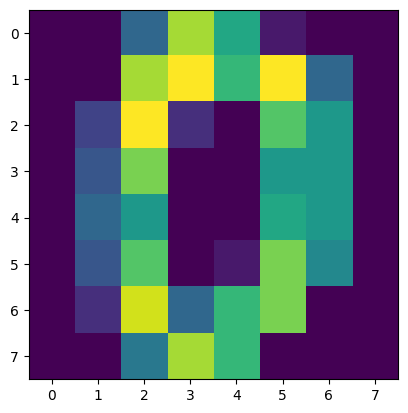

In [12]:
from sklearn import datasets

digits = datasets.load_digits()

print(digits.target[0])

plt.imshow(digits.data[0].reshape((8,8)))

**5. [0.1 балла]** Примените к матрице `digits.data` сингулярное разложение.

In [13]:
U, S, Vt = np.linalg.svd(digits.data, full_matrices=False)

**6. [0.65 балла]** Визуализируйте данные, спроецировав их на такую плоскость, чтобы координаты точек соответствовали первым двум новым признакам. Не забудьте покрасить точки, отвечающие различным цифрам, в разные цвета (если Вы любите красивые визуализации, разберитесь, как вместо точек рисовать маленькие цифры).

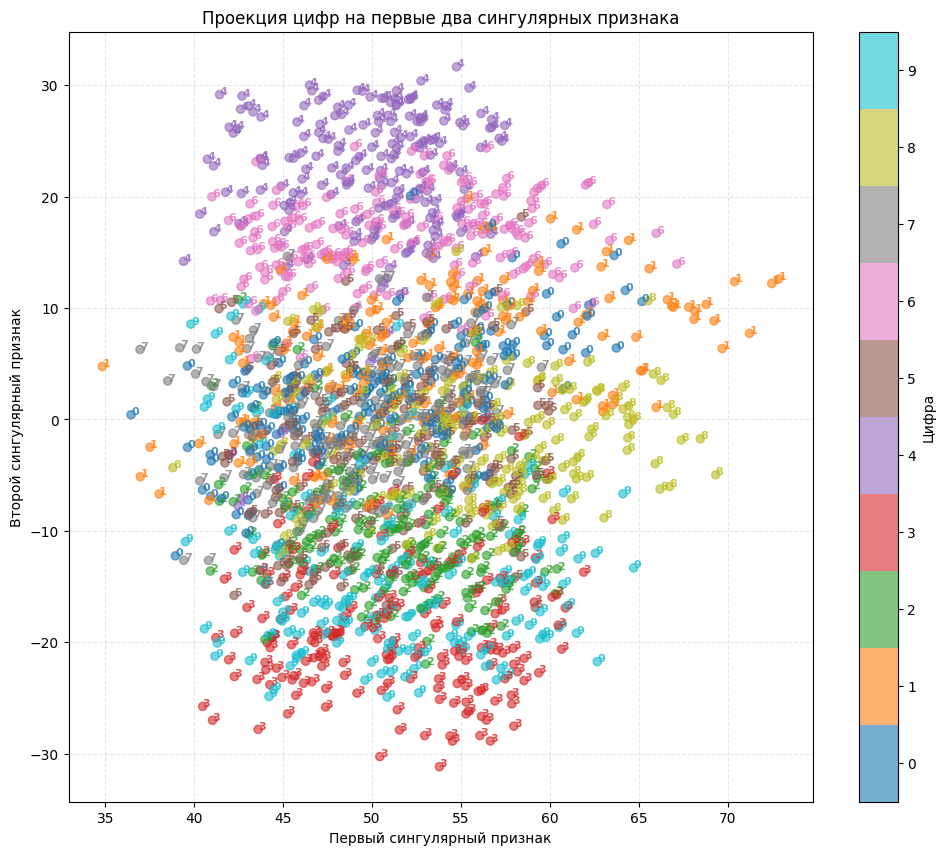

In [14]:
X_projected = U[:, :2] * S[:2]
plt.figure(figsize=(12, 10))

plt.scatter(X_projected[:, 0], X_projected[:, 1], c=digits.target, cmap='tab10', alpha=0.6)
plt.colorbar(label='Цифра', ticks=range(10))
plt.clim(-0.5, 9.5)
for i in range(digits.data.shape[0]):
    plt.text(X_projected[i, 0], X_projected[i, 1], str(digits.target[i]),
             color=plt.cm.tab10(digits.target[i] / 10.),
             fontdict={'weight': 'bold', 'size': 8},
             alpha=0.8)

plt.title('Проекция цифр на первые два сингулярных признака')
plt.xlabel('Первый сингулярный признак')
plt.ylabel('Второй сингулярный признак')
plt.grid(True, linestyle='--', alpha=0.3)

plt.show()

**7. [0.25 балла]** Теперь вычтите из каждого признака его среднее значение, снова сделайте SVD и нарисуйте разноцветные точки.

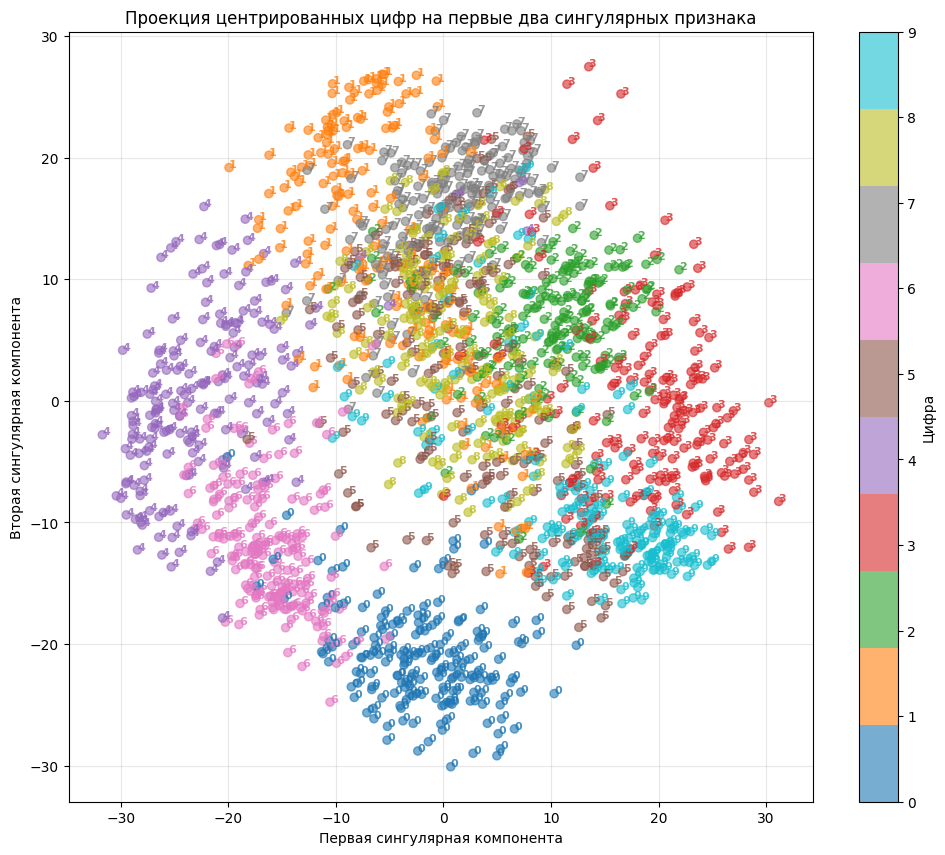

In [15]:
X = digits.data
y = digits.target
X_centered = X - np.mean(X, axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

X_projected = U[:, :2] * S[:2]

plt.figure(figsize=(12, 10))
scatter = plt.scatter(X_projected[:, 0], X_projected[:, 1], c=y, cmap='tab10', alpha=0.6)
for i in range(X.shape[0]):
    plt.text(X_projected[i, 0], X_projected[i, 1], str(y[i]),
             color=plt.cm.tab10(y[i]/10.),
             fontdict={'weight': 'bold', 'size': 8},
             alpha=0.8)
cbar = plt.colorbar(scatter)
cbar.set_ticks(range(10))
cbar.set_label('Цифра')
plt.title('Проекция центрированных цифр на первые два сингулярных признака')
plt.xlabel('Первая сингулярная компонента')
plt.ylabel('Вторая сингулярная компонента')
plt.grid(alpha=0.3)
plt.show()

**8. [0.25 балла]** Сравните выполненные Вами в двух предыдущих пунктах визуализации. Чем последняя выгодно отличается от первой?

Вторая визуализация выгодно отличается от первой тем, что до центрирования точки лежали в одной размытой куче, а после центрирования кучность уменьшилась — чётко проступили отдельные кластеры, соответствующие разным цифрам.

**9. [1 балл]** Сравните работу SVD с другим методом понижения размерности: [случайными гауссовскими проекциями](http://scikit-learn.org/stable/modules/generated/sklearn.random_projection.GaussianRandomProjection.html).

*Комментарий: Эксперименты без выводов, объясняющих полученные результаты, не оцениваются. Для получения полного балла за этот пункт постарайтесь провести как можно больше разноплановых экспериментов.*

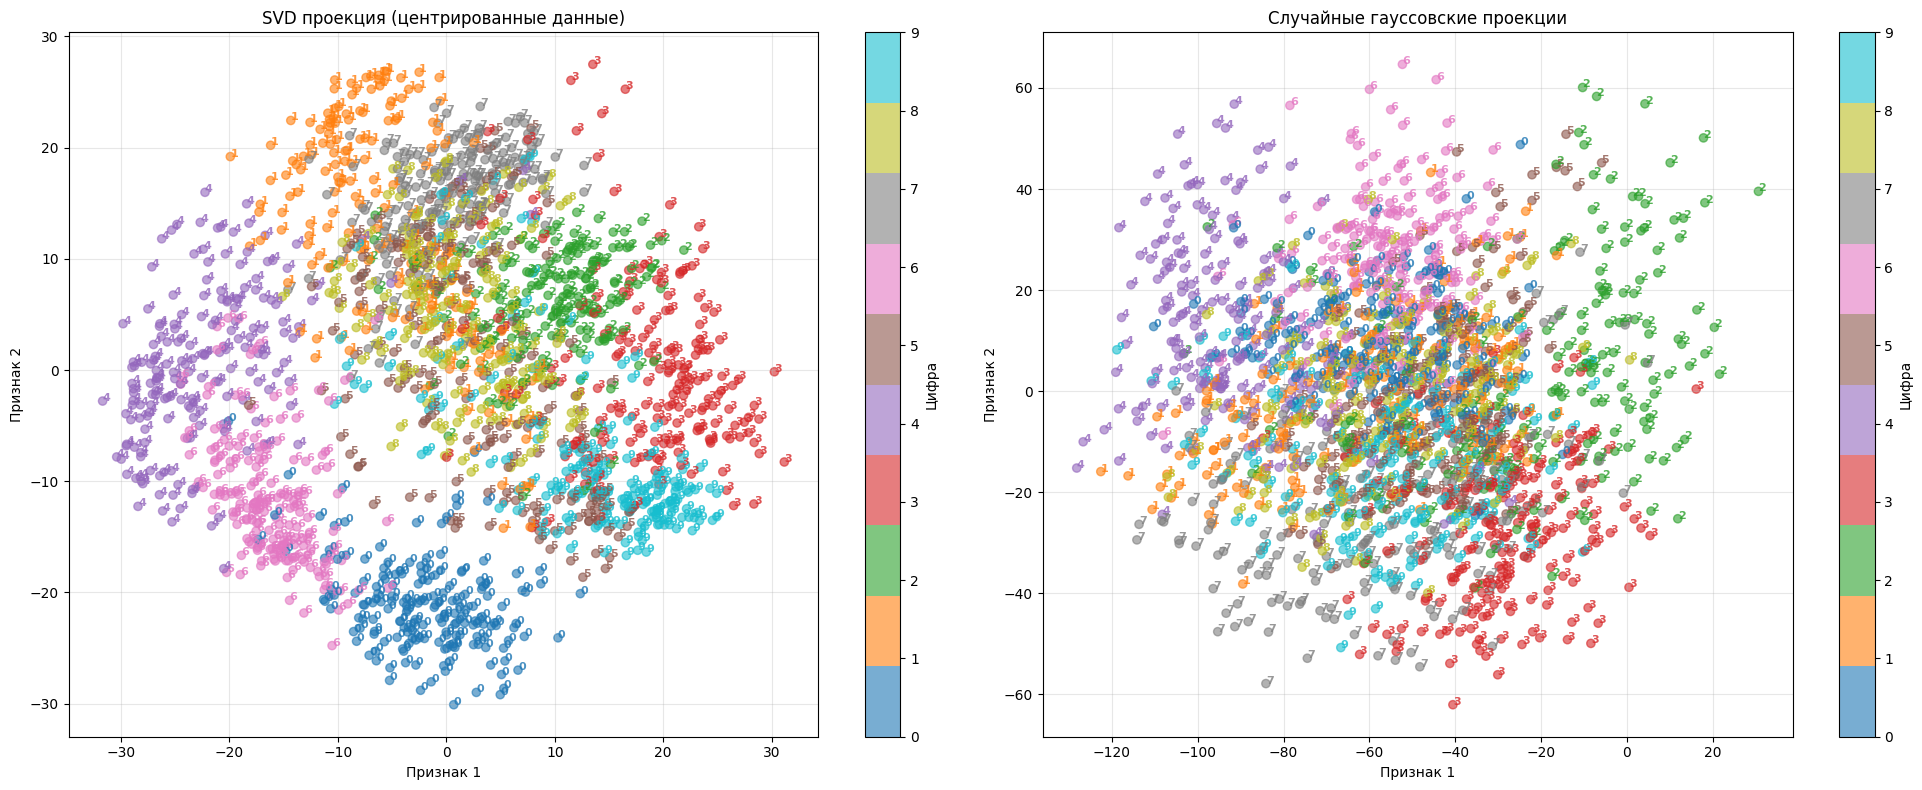


Метрики качества:
SVD Silhouette Score: 0.105
RP Silhouette Score: -0.040

Время выполнения:
SVD: 0.3341 сек
RP: 0.0027 сек


In [16]:
from sklearn.random_projection import GaussianRandomProjection
digits = datasets.load_digits()
X = digits.data
y = digits.target
X_centered = X - np.mean(X, axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
X_svd = U[:, :2] * S[:2]
rp = GaussianRandomProjection(n_components=2, random_state=42)
X_rp = rp.fit_transform(X)
def plot_digits_projection(X_proj, title, ax):
    scatter = ax.scatter(X_proj[:, 0], X_proj[:, 1], c=y, cmap='tab10', alpha=0.6)
    for i in range(X.shape[0]):
        ax.text(X_proj[i, 0], X_proj[i, 1], str(y[i]),
                color=plt.cm.tab10(y[i]/10.),
                fontdict={'weight': 'bold', 'size': 8},
                alpha=0.8)
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_ticks(range(10))
    cbar.set_label('Цифра')
    ax.set_title(title)
    ax.set_xlabel('Признак 1')
    ax.set_ylabel('Признак 2')
    ax.grid(alpha=0.3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

plot_digits_projection(X_svd, 'SVD проекция (центрированные данные)', ax1)
plot_digits_projection(X_rp, 'Случайные гауссовские проекции', ax2)

plt.tight_layout()
plt.show()

from sklearn.metrics import silhouette_score

print("\nМетрики качества:")
print(f"SVD Silhouette Score: {silhouette_score(X_svd, y):.3f}")
print(f"RP Silhouette Score: {silhouette_score(X_rp, y):.3f}")

import time

start = time.time()
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
svd_time = time.time() - start

start = time.time()
rp = GaussianRandomProjection(n_components=2, random_state=42).fit_transform(X)
rp_time = time.time() - start

print("\nВремя выполнения:")
print(f"SVD: {svd_time:.4f} сек")
print(f"RP: {rp_time:.4f} сек")

1. SVD осознанно проецирует данные так, чтобы максимально сохранить расстояния между точками.RP проецирует данные случайно, сохраняя расстояния лишь примерно. Из-за этого при RP точки лежат в размытой куче, а при SVD четко видны отдельные кластеры, соответствующие разным цифрам
2. SVD сохраняет глобальную структуру данных, точки внутри кластеров ближе друг к другу, чем к другим кластерам. RP Сохраняет расстояния приблизительно и может перемешать данные, если проекция неудачная. Поэтому у SVD Silhouette Score (качество) выше, чем у RP
3. Пусть мы разлагаем матрицу $X_{n\times d}$. Тогда сложность SVD $= O(\min(n^2d, nd^2))$ - зависит от того, строк или столбцов больше. RP умножает матрицу $X_{n \times d}$ на случайную матрицу $R_{d \times k}$, тогда сложность RP $=O(ndk)$. При больших $n, d: $ RP будет значительно быстрее, чем SVD, что также подтверждается экспериментом

### Задание 3. Когда SVD не сработает

**Disclaimer**

Цель этого задания — познакомить Вас не только с геометрическим смыслом сингулярного разложения, но и перекинуть очередной мостик между линейной алгеброй и анализом данных. К сожалению, на том берегу Вас встретят разные пока неизведанные понятия; мы постараемся по возможности дать какие-то определения, но, конечно, нет никакой возможности изложить на этих страницах полный курс теории вероятностей. Поэтому какие-то вещи останутся недосказанными или необоснованными; если Вам будет интересно, не стесняйтесь читать соответствующую литературу или хотя бы Википедию, а если нет, то мы надеемся, что хотя бы наглядное представление у Вас сформируется. В любом случае, нам хотелось бы, чтобы воспоминания об этом всколыхнулись в ваших головах, когда Вы будете это всё изучать в курсе по теории вероятностей.

Но начнём мы с того, что обсудим ситуацию, в которой SVD работает лучше всего: а именно, со случая, когда данные распределены нормально.

**Что такое плотность вероятности**

В дальнейшем Вам достаточно часто придётся сталкиваться со *случайными величинами*. Мы не будем сейчас пытаться строго определить, что это такое (для этого у вас будет целый курс по теории вероятностей), а остановимся только на одном его аспекте.

Если случайная величина $X$ принимает лишь конечное (или счётное) число значений $x_1,x_2,\ldots$, то чтобы задать её, достаточно описать, с какой вероятностью $X$ равна $x_i$:

$$p_i = P(X = x_i)$$

таким образом, чтобы $\sum_ip_i = 1$. Если же $X$ принимает значения на каком-либо отрезке или на всей числовой прямой, то так уже не получится: в этом случае вероятность того, что $X$ равна какому-то конкретному $x_0$, обычно равна нулю. Как правило, заменой вероятностей $p_i$ служит *функция плотности распределения* $p(x)$. Смысл её таков:

$$P(\alpha\leqslant X\leqslant\beta) = \int\limits_{\alpha}^{\beta}p(x)dx$$

(в левой части стоит вероятность того, что значение $X$ лежит на отрезке $[\alpha,\beta]$).

Таким образом, функция $p(x)$ действительно играет роль "плотности": вероятность попасть в отрезок одной и той же длины тем выше, чем больше значения $p(x)$ на нём.

**Нормальное распределение**

Одним из самых важных примеров непрерывных распределений является *нормальное распределение*. Его плотность имеет вид

$$p(x) = \frac1{\sqrt{2\pi\sigma^2}}e^{-\frac{(x - a)^2}{2\sigma^2}}$$

У него есть два параметра:

- $a$ - *математическое ожидание*, имеющее смысл среднего значения и для нормального распределения совпадающее с центром симметрии распределения;
- $\sigma^2$ - *дисперсия*: чем она меньше, тем в большей степени распределение сконцентрировано подле своего математического ожидания

Нормальное распределение с параметрами $a$ и $\sigma^2$ можно кратко обозначать $\mathcal{N}(a, \sigma^2)$.

Чтобы проиллюстрировать это, мы сгененерируем много точек из распределений $\mathcal{N}(2, 0.25)$, $\mathcal{N}(0, 1)$ и $\mathcal{N}(0, 4)$ и по ним в каждом из этих случаев построим аппроксимацию функции плотности распределения. Обратите внимание, что параметр $a$ в `numpy` называется `loc`, $\sigma$ (без квадрата!) — `scale`

In [17]:
import numpy as np
from scipy.interpolate import UnivariateSpline
from matplotlib import pyplot as plt
%matplotlib inline
import seaborn as sns

<ipython-input-18-5545a14a65cb>:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(s, hist=False, kde=True,
<ipython-input-18-5545a14a65cb>:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(s, hist=False, kde=True,
<ipython-input-18-5545a14a65cb>:14: UserWarning: 

`distplot` is a

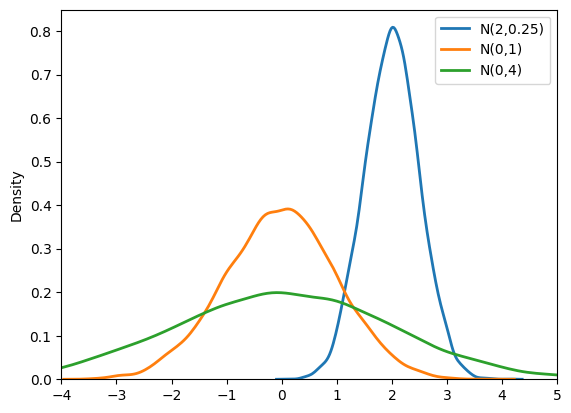

In [18]:
N = 10000
plt.xlim([-4,5])
s = np.random.normal(loc=2, scale=0.5, size=N)   # generate your data sample with N elements
sns.distplot(s, hist=False, kde=True,
             bins=50,
             kde_kws={'linewidth': 2}, label='N(2,0.25)')

s = np.random.normal(loc=0, scale=1, size=N)   # generate your data sample with N elements
sns.distplot(s, hist=False, kde=True,
             bins=50,
             kde_kws={'linewidth': 2}, label='N(0,1)')

s = np.random.normal(loc=0, scale=2, size=N)   # generate your data sample with N elements
sns.distplot(s, hist=False, kde=True,
             bins=50,# color = 'darkblue',
             kde_kws={'linewidth': 2}, label='N(0,4)')

plt.legend()
plt.show()

**Функция плотности распределения в многомерном случае**

Если значения случайной величины $X$ — это многомерные векторы, функция плотности сохраняет примерно тот же смысл: если $\Omega\subseteq\mathbb{R}^n$, то

$$P(X\in\Omega) = \int\limits_{\Omega}p(x)dx$$

**Многомерное нормальное распределение**

Многомерное нормальное распределение определяется также двумя параметрами: *вектором средних* $a$ и положительно определённой *ковариационной матрицей* $\Sigma$; оно имеет плотность

$$p(x) = \frac1{(2\pi)^{n/2}|\Sigma|^{1/2}}e^{-\frac12(x - a)^T\Sigma^{-1}(x - a)}$$

где, напомним, $x$ — вектор из $\mathbb{R}^n$. Компоненты вектора $a$ — это математические ожидания отдельных координат $X$, а на диагонали матрицы $\Sigma$ стоят их *дисперсии* (настоящие, без кавычек). Вне диагонали стоят *ковариации* компонент $X$ (пока вам достаточно понимать, что если они равны нулю, то эти компоненты независимы$^1$).

---
$^1$ Точнее сказать, некоррелированны, однако для компонент многомерного нормального распределения независимость и некоррелированность равносильны (на самом деле редкое и удачное свойство!).

**Несколько фактов**

* Под (n-1)-мерным эллипсоидом будем понимать гиперповерхность в $\mathbb{R}^n$, такую что в некоторой прямоугольной декартовой системе координат её уравнение принимает вид $\sum_{i=1}^n \frac{x_i^2}{r_i^2} = 1$. Поверхности уровня $p(x) = c$ — это эллипсоиды.

*  Пользуясь теоремой о приведении квадратичной формы к главным осям, можно показать, что функция плотности многомерного нормального распределения представляется в виде произведения одномерных нормальных плотностей при переходе в новую систему координат.
$$p(x)=\frac1{(2\pi)^{n/2}|\Sigma|^{1/2}}e^{-\frac12(x - a)^T\Sigma^{-1}(x - a)}\:\underset{\text{новая система координат}}{\to}\: p(x)=p(x_1)\cdot ...\cdot p(x_n)$$

    В частности, это означает, что с помощью замены координат можно добиться того, чтобы отдельные компоненты были независимы (то есть матрица ковариации $\Sigma$ диагональна).

А мы тем временем продемонстрируем это на конкретном примере, сгенерировав много точек из двумерного нормального распределения с вектором средних $(-1,3)$ и ковариационной матрицей

$$\begin{pmatrix}
1 & \frac32\\
\frac32 & 5
\end{pmatrix}$$

и нарисовав приближённо линии уровня функции плотности.

<Axes: >

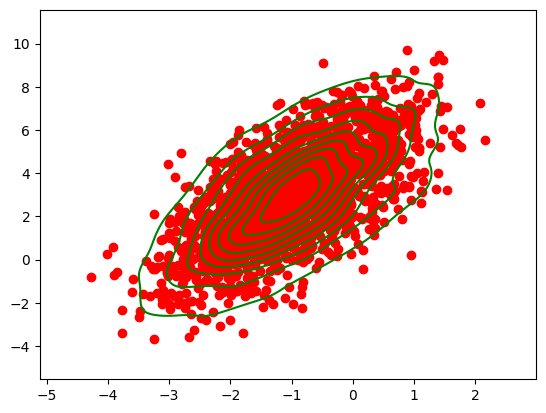

In [19]:
import seaborn as sns
import numpy as np

N = 2000
s = np.random.multivariate_normal(mean=np.array([-1,3]), cov=np.array([[1,1.5],[1.5,5]]), size=N)
plt.scatter(s[:,0], s[:,1], color='red')
sns.kdeplot(x=s[:, 0], y=s[:, 1], fill=False, color='g')

Как видите, линии уровня весьма напоминают эллипсы (только напоминают, потому что точек у нас всё-таки конечное число).

**1. [0 баллов]** Сгенерируйте выборку из 1000 точек $x_1,\ldots,x_{1000}$ из нормального распределения с вектором средних $a = (0,0)$ и ковариационной матрицей

$$\Sigma = \begin{pmatrix}
1 & -2\\
-2 & 5
\end{pmatrix}.$$

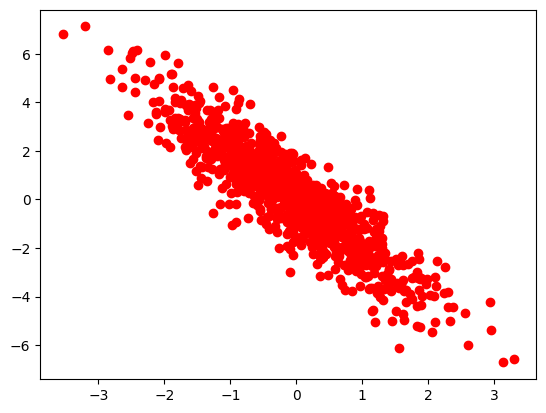

In [20]:
N = 1000
s = np.random.multivariate_normal(mean=np.array([0,0]), cov=np.array([[1,-2],[-2,5]]), size=N)
plt.scatter(s[:,0], s[:,1], color='red')

**2. [0.25 балла]** Сделайте SVD-разложение $X = U\Sigma V^T$. Нарисуйте на плоскости все точки $x_i$ и направления новых признаков. Убедитесь, что направления новых признаков примерно совпадают с направлениями полуосей эллипса, образованного точками.

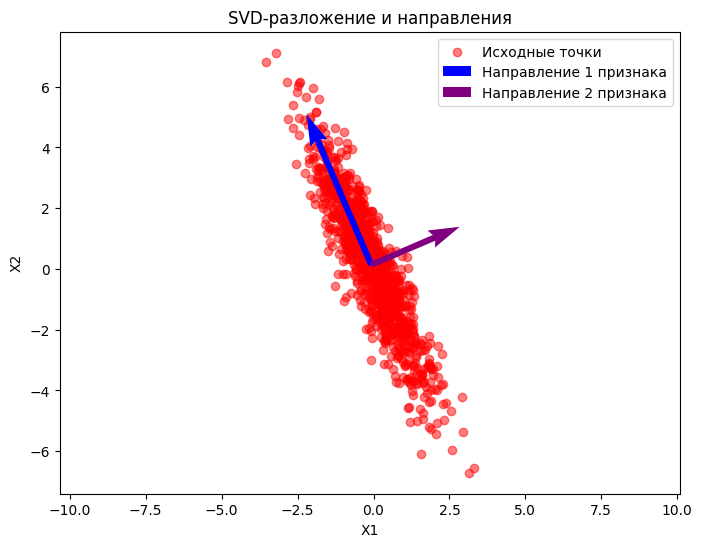

In [21]:
X = s - np.mean(s, axis=0)
U, Sigma, Vt = svd(X)
plt.figure(figsize=(8, 6))
plt.scatter(s[:, 0], s[:, 1], color='red', alpha=0.5, label='Исходные точки')
center = np.mean(s, axis=0)
plt.quiver(*center, *Vt[0]*Sigma[0]/14,
           color='blue', scale=1, scale_units='xy',
           width=0.01, label='Направление 1 признака')

plt.quiver(*center, *Vt[1]*Sigma[1]/4,
           color='purple', scale=1, scale_units='xy',
           width=0.01, label='Направление 2 признака')
plt.title('SVD-разложение и направления')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.axis('equal')
plt.show()

**3. [0.5 балла]** Приведите к главным осям матрицу ковариации (это нужно сделать без привлечения `Python`) и убедитесь, что направления этих осей тоже примерно совпадают с наблюдаемыми направлениями полуосей эллипсоида.

$A = \begin{pmatrix}
    1 & -2\\-2 & 5
\end{pmatrix}$ - приведем к главным осям

$\det (A-\lambda E) = \left| \begin{matrix}
    1 -\lambda & -2\\-2  & 5-\lambda
\end{matrix}\right| = (\lambda - (3-2\sqrt{2}))(\lambda - (3+2\sqrt{2})) \Rightarrow \lambda_1 = 3-2\sqrt{2}; \lambda_2 = 3+2\sqrt{2}$

$A-(3-2\sqrt{2})E = \begin{pmatrix}
    2\sqrt{2}-2 & -2\\-2 & 2\sqrt{2}+2
\end{pmatrix} \iff \begin{pmatrix}
    1 & -\sqrt{2}-1\\0 & 0
\end{pmatrix} \Rightarrow $ ФСР: $\begin{pmatrix} \sqrt{2}+1\\1\end{pmatrix} = v_1; e_1 = \frac{v_1}{|v_1|}$ - ортонормированный базис собственного подпространства

$A-(3+2\sqrt{2})E = \begin{pmatrix}
    -2\sqrt{2}-2 & -2\\-2 & -2\sqrt{2}+2
\end{pmatrix} \iff \begin{pmatrix}
    1 & \sqrt{2}-1\\0 & 0
\end{pmatrix} \Rightarrow $ ФСР: $\begin{pmatrix} -\sqrt{2}+1\\1\end{pmatrix} = v_2; e_2 = \frac{v_2}{|v_2|}$ - ортонормированный базис собственного подпространства

Тогда в базисе $(e_1,e_2)$ матрица имеет вид $\begin{pmatrix}
    3-2\sqrt{2} & 0\\0 & 3+2\sqrt{2}
\end{pmatrix}$

Главные оси: $\langle e_1\rangle; \langle e_2\rangle = \left\langle \begin{pmatrix} \sqrt{2}+1\\1\end{pmatrix}\right\rangle; \left\langle \begin{pmatrix} -\sqrt{2}+1\\1\end{pmatrix}\right\rangle$ - примерно совпадают с направлениями осей эллипсоида

Как Вы могли убедиться, SVD хорошо справляется со своей работой, когда данные распределены нормально, а в других случаях может давать совсем не такие информативные (или даже не адекватные) результаты.

**4. [0.25 балла]** Сгенерируйте двумерную выборку, представляющую собой два расположенных рядом (см. пример ниже) длинных и узких не пересекающихся эллипса с центрами в точках $(-1,0)$ и $(1,0)$ и с параллельными направлениями полуосей. Иными словами, постарайтесь как можно точнее воспроизвести картинку ниже.

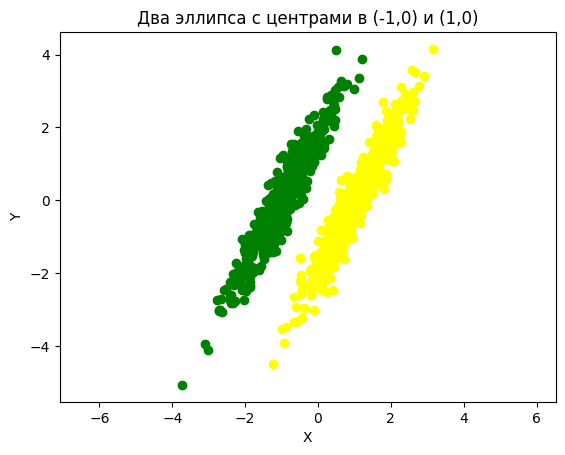

In [22]:
N = 500
cov1 = np.array([[0.55, 1],[1, 2]])
s1 = np.random.multivariate_normal(mean=np.array([-1, 0]), cov=cov1, size=N)
s2 = np.random.multivariate_normal(mean=np.array([1, 0]), cov=cov1, size=N)
plt.scatter(s1[:,0], s1[:,1], color='green')
plt.scatter(s2[:,0], s2[:,1], color='yellow')
plt.title('Два эллипса с центрами в (-1,0) и (1,0)')
plt.xlabel('X')
plt.ylabel('Y')
plt.axis('equal')
plt.show()

**5. [0.1 балла]** Сделайте SVD и нарисуйте направления новых признаков.

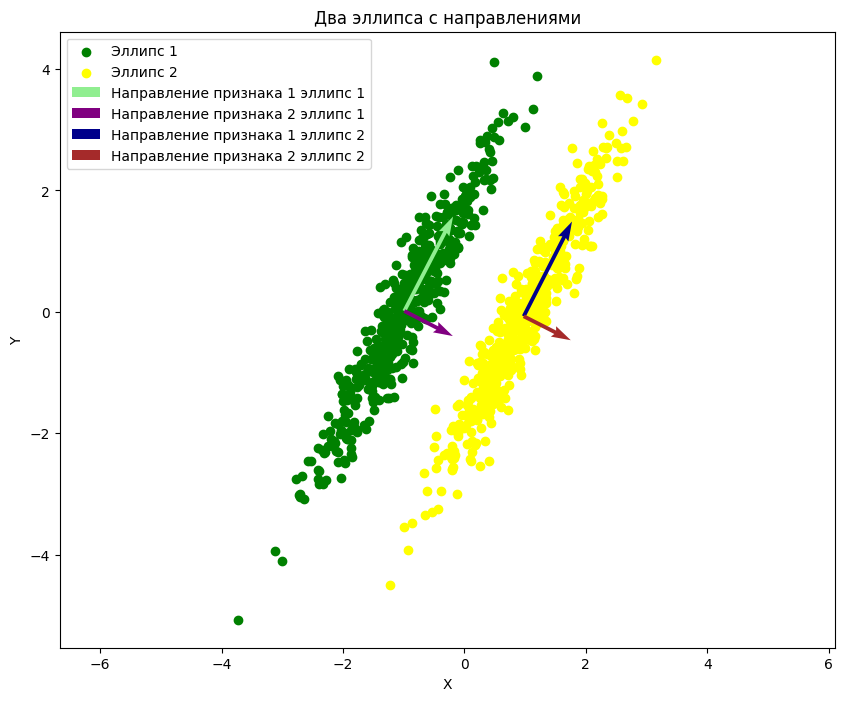

In [23]:
s1_centered = s1 - np.mean(s1, axis=0)
s2_centered = s2 - np.mean(s2, axis=0)
U1, S1, Vt1 = np.linalg.svd(s1_centered)
U2, S2, Vt2 = np.linalg.svd(s2_centered)
plt.figure(figsize = (10,8))
plt.scatter(s1[:, 0], s1[:, 1], color='green', label='Эллипс 1')
plt.scatter(s2[:, 0], s2[:, 1], color='yellow', label='Эллипс 2')
center1 = np.mean(s1, axis=0)
center2 = np.mean(s2, axis=0)
scale_factor = 200
plt.quiver(*center1, Vt1[0,0]*S1[0]/20, Vt1[0,1]*S1[0]/20,
           color='lightgreen', scale=1, scale_units='xy', width=0.005,
           label='Направление признака 1 эллипс 1')
plt.quiver(*center1, Vt1[1,0]*S1[1]/5, Vt1[1,1]*S1[1]/5,
           color='purple', scale=1, scale_units='xy', width=0.005,
           label='Направление признака 2 эллипс 1')
plt.quiver(*center2, Vt2[0,0]*S2[0]/20, Vt2[0,1]*S2[0]/20,
           color='darkblue', scale=1, scale_units='xy', width=0.005, label='Направление признака 1 эллипс 2')
plt.quiver(*center2, Vt2[1,0]*S2[1]/5, Vt2[1,1]*S2[1]/5,
           color='brown', scale=1, scale_units='xy', width=0.005, label='Направление признака 2 эллипс 2')

plt.title('Два эллипса с направлениями')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.axis('equal')
plt.show()

Если бы мы решали задачу анализа данных, то скорее всего нас интересовал признак, который бы разделял два кластера (в данном случае два эллипса), то есть такая функция $f(x)$, для которой
$$f(x) < c,\ \mbox{если объект $x$ из первого класса}$$
$$f(x) > c,\ \mbox{если объект $x$ из второго класса}$$
для некоторого числа $c$.

**6. [0.25 балла]** Помогает ли какой-нибудь из двух предоставленных SVD признаков обнаружить эту структуру? Обязательно поясните свой ответ.

 Оба эллипса имеют одинаковую ковариационную матрицу, поэтому их главные компоненты параллельны .
При проецировании точек на любую из главных компонент, распределения обоих эллипсов сильно перекрываются, поэтому никакой из двух признаков не поможет. Визуализация:

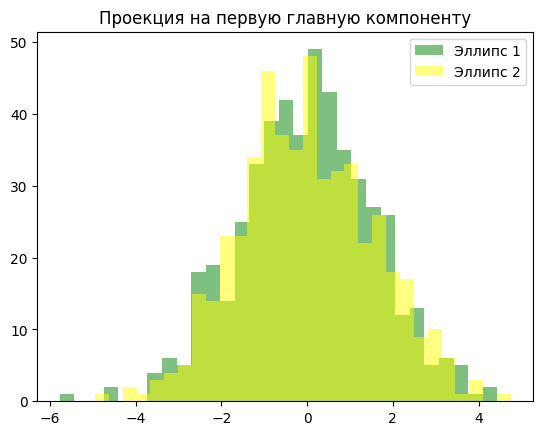

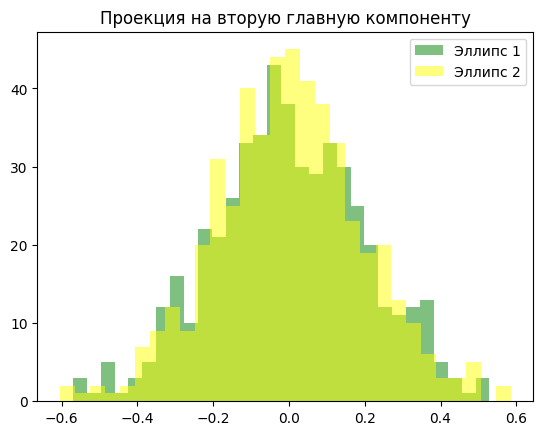

In [25]:
proj1 = s1_centered @ Vt1[0]
proj2 = s2_centered @ Vt1[0]
plt.hist(proj1, bins=30, alpha=0.5, color='green', label='Эллипс 1')
plt.hist(proj2, bins=30, alpha=0.5, color='yellow', label='Эллипс 2')
plt.title('Проекция на первую главную компоненту')
plt.legend()
plt.show()
proj11 = s1_centered @ Vt1[1]
proj21 = s2_centered @ Vt1[1]
plt.hist(proj11, bins=30, alpha=0.5, color='green', label='Эллипс 1')
plt.hist(proj21, bins=30, alpha=0.5, color='yellow', label='Эллипс 2')
plt.title('Проекция на вторую главную компоненту')
plt.legend()
plt.show()

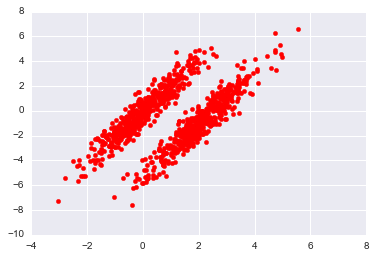

In [ ]:
# Just keep this image as a sample

**7. [0 баллов]** Сгенерируйте выборку из 1000 точек $x_1,\ldots,x_{1000}$ из нормального распределения с вектором средних $a = (1,1)$ и ковариационной матрицей

$$\Sigma = \begin{pmatrix}
1 & 0\\
0 & 4
\end{pmatrix}.$$

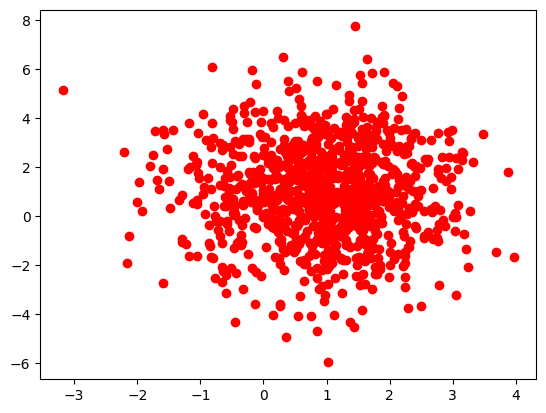

In [26]:
N = 1000
s = np.random.multivariate_normal(mean=np.array([1,1]), cov=np.array([[1,0],[0,4]]), size=N)
plt.scatter(s[:,0], s[:,1], color='red')

**8. [0.2 балла]** Очевидно, что "интересными" для этого датасета направлениями будут направления полуосей эллипса-облака точек. Глядя только на матрицу $\Sigma$, определите, что это будут за направления? Поясните свой ответ.

Направления полуосей эллипса-облака соответствуют главным осям — направлениям, в которых ковариационная матрица становится диагональной.
В данном случае матрица уже диагональна в стандартном базисе (оси $Ox$ и $Oy$), что означает, что направления полуосей совпадают с направлениями векторов стандартного базиса - осью $Ox$ и осью $Oy$.

**9. [0.1 балла]** Сделайте SVD-разложение $X = U\Sigma V^T$. Нарисуйте все точки $x_i$ на плоскости и направления новых признаков.

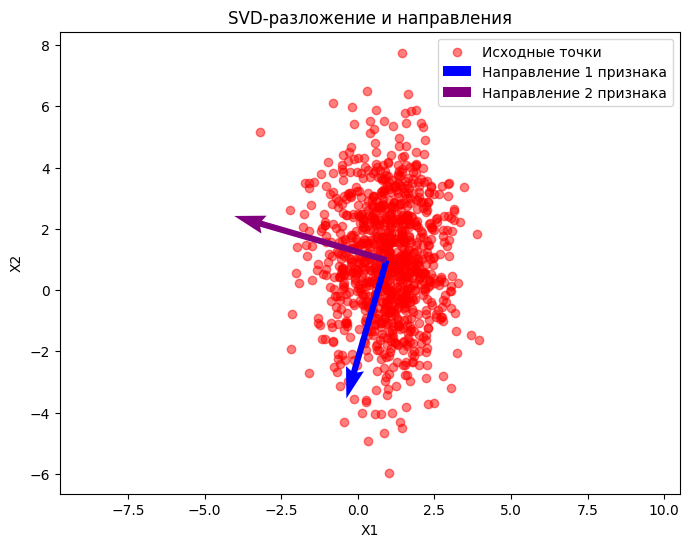

In [27]:
X = s
U, Sigma, Vt = svd(X)
plt.figure(figsize=(8, 6))
plt.scatter(s[:, 0], s[:, 1], color='red', alpha=0.5, label='Исходные точки')
center = np.mean(s, axis=0)
plt.quiver(*center, *Vt[0]*Sigma[0]/15,
           color='blue', scale=1, scale_units='xy',
           width=0.01, label='Направление 1 признака')

plt.quiver(*center, *Vt[1]*Sigma[1]/8,
           color='purple', scale=1, scale_units='xy',
           width=0.01, label='Направление 2 признака')
plt.title('SVD-разложение и направления')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.axis('equal')
plt.show()

**10. [0.4 балла]** Сделайте вывод: в чём проблема и как можно её исправить?

Видно, что направления признаков не совпадают с главными полуосями эллипса. Чтобы решить эту проблему, нужно центрировать данные, тогда после применения SVD направления признаков будут совпадать с главными полуосями. На всякий случай проверим:

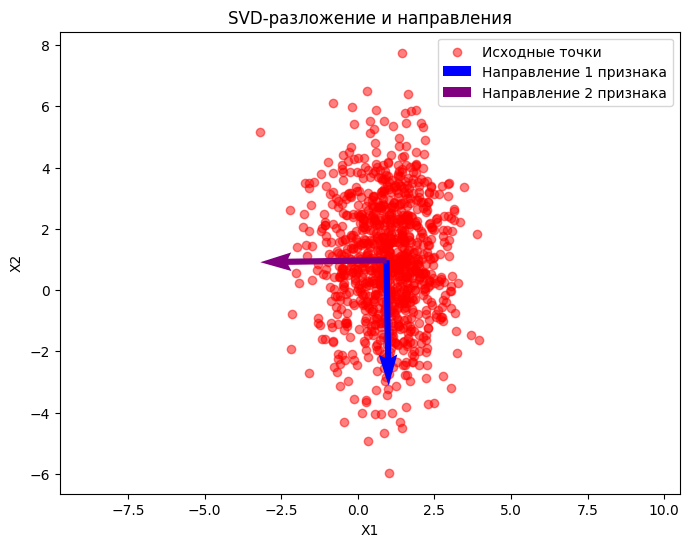

In [28]:
X = s- np.mean(s, axis=0)
U, Sigma, Vt = svd(X)
plt.figure(figsize=(8, 6))
plt.scatter(s[:, 0], s[:, 1], color='red', alpha=0.5, label='Исходные точки')
center = np.mean(s, axis=0)
plt.quiver(*center, *Vt[0]*Sigma[0]/15,
           color='blue', scale=1, scale_units='xy',
           width=0.01, label='Направление 1 признака')

plt.quiver(*center, *Vt[1]*Sigma[1]/8,
           color='purple', scale=1, scale_units='xy',
           width=0.01, label='Направление 2 признака')
plt.title('SVD-разложение и направления')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.axis('equal')
plt.show()